# 02 — EDA & Sentiment Scoring: Data Berita S&P 500

Notebook ini melakukan:
1. **EDA** pada `data/raw/news/sp500_headlines_2008_2024.csv` (headline berita keuangan S&P 500, 2008–2024).
2. **Sentiment scoring per-headline** memakai **FinBERT** (`ProsusAI/finbert`, snapshot lokal) via utilitas `TextPreprocessor`.
3. **Agregasi harian** skor sentimen — dengan metode **probability-weighted** (skor di-bobot oleh confidence FinBERT, bukan sekadar rata-rata -1/0/1).

> **Catatan:** Notebook ini ditulis untuk dijalankan manual (Run). Semua cell belum dieksekusi. Tidak ada file CSV/project yang ditulis — output sentimen harian disimpan sebagai DataFrame di memori.

## 0. Setup

In [31]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Notebook dijalankan dari folder notebooks/ -> root project = parent
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_RAW = PROJECT_ROOT / 'data' / 'raw' / 'news' / 'sp500_headlines_2008_2024.csv'
# TextPreprocessor auto-resolves HuggingFace cache path -> snapshot subdir
FINBERT_PATH = PROJECT_ROOT / 'models' / 'finbert' / 'models--ProsusAI--finbert'

print('PROJECT_ROOT :', PROJECT_ROOT)
print('DATA_RAW     :', DATA_RAW, '| exists:', DATA_RAW.exists())
print('FINBERT_PATH :', FINBERT_PATH, '| exists:', FINBERT_PATH.exists())

PROJECT_ROOT : /home/forecasting_index_snp500/stock_prediction
DATA_RAW     : /home/forecasting_index_snp500/stock_prediction/data/raw/news/sp500_headlines_2008_2024.csv | exists: True
FINBERT_PATH : /home/forecasting_index_snp500/stock_prediction/models/finbert/models--ProsusAI--finbert | exists: True


## 1. Exploratory Data Analysis (EDA)

Rentang penuh **2008–2024** (tidak difilter per tahun).

### 1.1 Load Data

In [32]:
df = pd.read_csv(DATA_RAW, parse_dates=['Date'])
print('Shape :', df.shape)
print('Kolom :', list(df.columns))
print('Rentang tanggal :', df['Date'].min().date(), '->', df['Date'].max().date())
print('Jumlah hari unik:', df['Date'].nunique())
df.head(10)

Shape : (19127, 3)
Kolom : ['Title', 'Date', 'CP']
Rentang tanggal : 2008-01-02 -> 2024-03-04
Jumlah hari unik: 3507


,Title,Date,CP
0,"JPMorgan Predicts 2008 Will Be ""Nothing But Net""",2008-01-02,1447.16
1,Dow Tallies Biggest First-session-of-year Poin...,2008-01-02,1447.16
2,2008 predictions for the S&P 500,2008-01-02,1447.16
3,"U.S. Stocks Higher After Economic Data, Monsan...",2008-01-03,1447.16
4,U.S. Stocks Climb As Hopes Increase For More F...,2008-01-07,1416.18
5,How Investing in Intangibles -- Like Employee ...,2008-01-09,1409.13
6,Head And Shoulders Top Bodes Ill For Bulls,2008-01-09,1409.13
7,U.S. Stocks Zigzag Higher As Bernanke Speech S...,2008-01-10,1420.33
8,It's a Black Monday as stock markets tank in e...,2008-01-22,1310.50
9,U.S. Stocks Largely Recover From Early Plunge,2008-01-22,1310.50


### 1.2 Missing Values & Duplikat

In [33]:
print('=== Info ===')
df.info()
print('\n=== Missing values ===')
print(df.isnull().sum())
print('\n=== Duplikat ===')
print('Baris duplikat penuh   :', df.duplicated().sum())
print('Headline (Title) dobel :', df['Title'].duplicated().sum())
print('Pasangan Title+Date dobel:', df.duplicated(subset=['Title', 'Date']).sum())

=== Info ===
<class 'pandas.DataFrame'>
RangeIndex: 19127 entries, 0 to 19126
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Title   19127 non-null  str           
 1   Date    19127 non-null  datetime64[us]
 2   CP      19127 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 1.5 MB

=== Missing values ===
Title    0
Date     0
CP       0
dtype: int64

=== Duplikat ===
Baris duplikat penuh   : 974
Headline (Title) dobel : 1073
Pasangan Title+Date dobel: 974


### 1.3 Distribusi Berita per Tahun

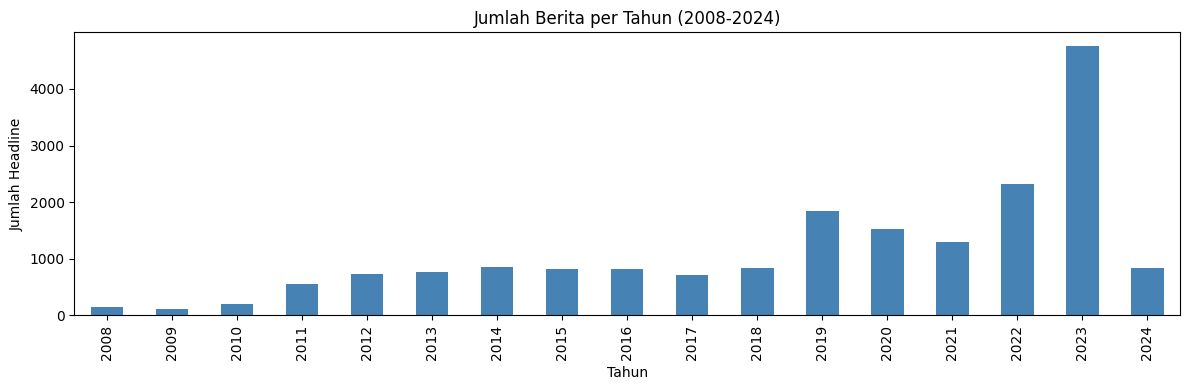

Year
2008     141
2009     113
2010     209
2011     547
2012     724
2013     776
2014     858
2015     818
2016     813
2017     706
2018     840
2019    1848
2020    1519
2021    1303
2022    2319
2023    4760
2024     833
dtype: int64

In [34]:
df['Year'] = df['Date'].dt.year
news_per_year = df.groupby('Year').size()

fig, ax = plt.subplots(figsize=(12, 4))
news_per_year.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Jumlah Berita per Tahun (2008-2024)')
ax.set_xlabel('Tahun'); ax.set_ylabel('Jumlah Headline')
plt.tight_layout(); plt.show()

news_per_year

### 1.4 Distribusi Berita per Hari

Rata-rata berita/hari : 5.45
Median berita/hari    : 4
Maks berita/hari      : 55
Min berita/hari       : 1


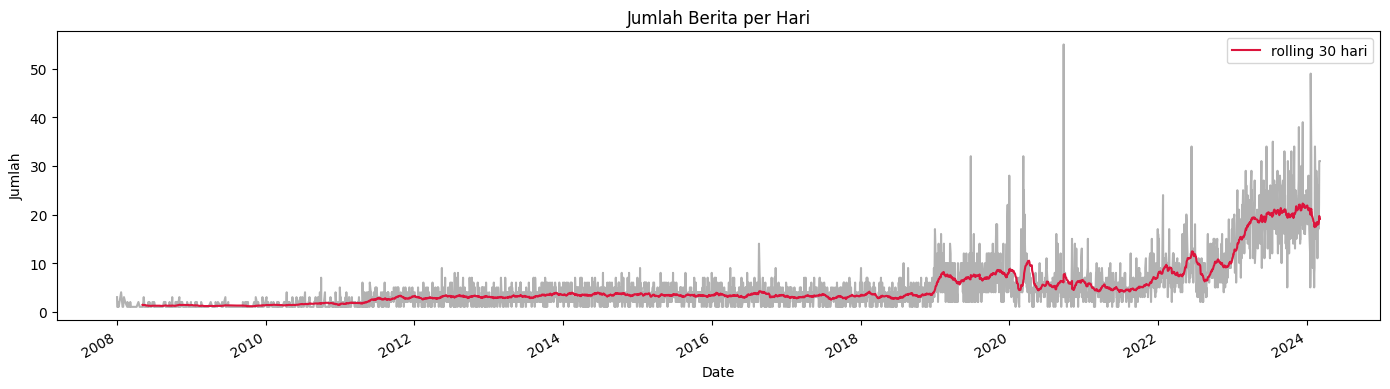

In [35]:
news_per_day = df.groupby('Date').size()
print(f'Rata-rata berita/hari : {news_per_day.mean():.2f}')
print(f'Median berita/hari    : {news_per_day.median():.0f}')
print(f'Maks berita/hari      : {news_per_day.max()}')
print(f'Min berita/hari       : {news_per_day.min()}')

fig, ax = plt.subplots(figsize=(14, 4))
news_per_day.plot(ax=ax, color='gray', alpha=0.6)
news_per_day.rolling(30).mean().plot(ax=ax, color='crimson', label='rolling 30 hari')
ax.set_title('Jumlah Berita per Hari'); ax.set_ylabel('Jumlah'); ax.legend()
plt.tight_layout(); plt.show()

### 1.5 Distribusi Panjang Headline

       title_len_char  title_len_word
count    19127.000000    19127.000000
mean        60.291421       10.500601
std         19.517099        3.470629
min          6.000000        1.000000
25%         46.000000        8.000000
50%         58.000000       10.000000
75%         71.000000       13.000000
max        172.000000       33.000000


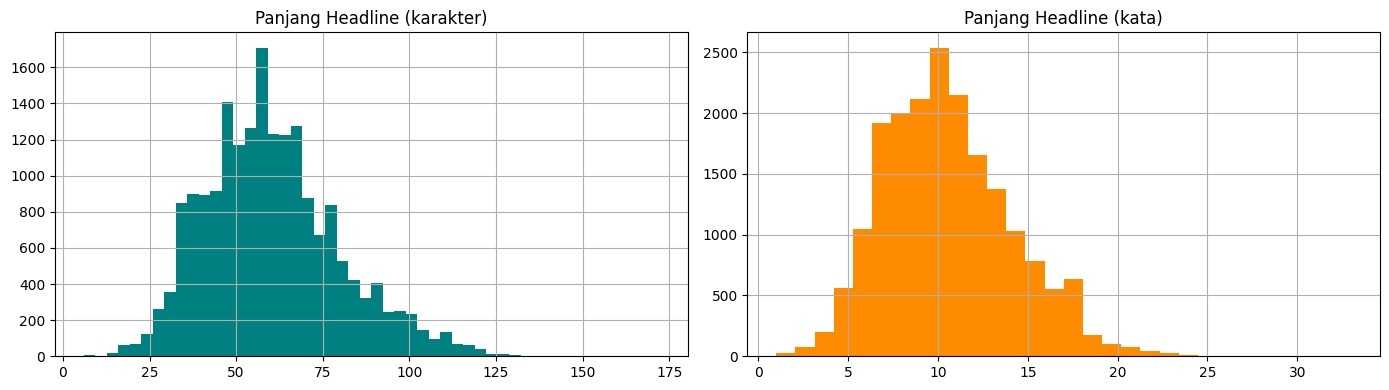

In [36]:
df['title_len_char'] = df['Title'].str.len()
df['title_len_word'] = df['Title'].str.split().str.len()

print(df[['title_len_char', 'title_len_word']].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['title_len_char'].hist(bins=50, ax=axes[0], color='teal')
axes[0].set_title('Panjang Headline (karakter)')
df['title_len_word'].hist(bins=30, ax=axes[1], color='darkorange')
axes[1].set_title('Panjang Headline (kata)')
plt.tight_layout(); plt.show()

### 1.6 Closing Price S&P 500 (kolom CP)

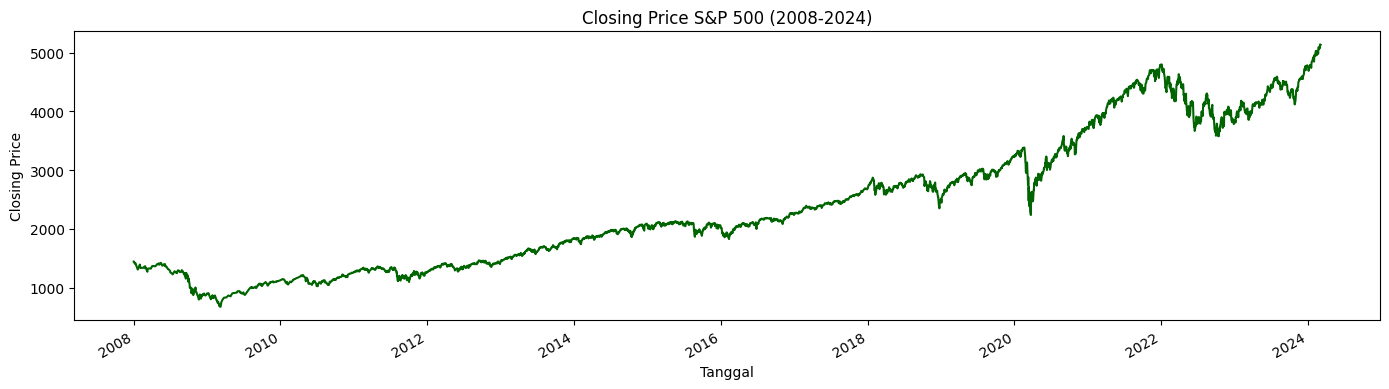

In [37]:
cp_daily = df.groupby('Date')['CP'].first()

fig, ax = plt.subplots(figsize=(14, 4))
cp_daily.plot(ax=ax, color='darkgreen')
ax.set_title('Closing Price S&P 500 (2008-2024)')
ax.set_xlabel('Tanggal'); ax.set_ylabel('Closing Price')
plt.tight_layout(); plt.show()

## 2. Text Preprocessing & FinBERT Sentiment Scoring

Setiap headline diberi skor oleh **FinBERT** → menghasilkan `sentiment_label` (positive/neutral/negative),
`sentiment_score` (probabilitas kelas pemenang) dan `sentiment_numeric` (+1/0/-1).

### 2.1 Cleaning: normalisasi, buang duplikat & headline terlalu pendek

In [38]:
import re

def clean_headline(text: str) -> str:
    text = str(text).strip()
    text = re.sub(r'\s+', ' ', text)   # collapse whitespace
    return text

work = df[['Date', 'Title']].copy()
work['Title'] = work['Title'].map(clean_headline)

before = len(work)
work = work.dropna(subset=['Title'])
work = work[work['Title'].str.len() > 0]
work = work.drop_duplicates(subset=['Title', 'Date'])

MIN_WORDS = 3
mask_short = work['Title'].str.split().str.len() < MIN_WORDS
print(f'Headline < {MIN_WORDS} kata dibuang : {mask_short.sum()}')
work = work[~mask_short].reset_index(drop=True)

print(f'Sebelum cleaning : {before}')
print(f'Sesudah cleaning : {len(work)}')
work.head()

Headline < 3 kata dibuang : 24
Sebelum cleaning : 19127
Sesudah cleaning : 18129


,Date,Title
0,2008-01-02,"JPMorgan Predicts 2008 Will Be ""Nothing But Net"""
1,2008-01-02,Dow Tallies Biggest First-session-of-year Poin...
2,2008-01-02,2008 predictions for the S&P 500
3,2008-01-03,"U.S. Stocks Higher After Economic Data, Monsan..."
4,2008-01-07,U.S. Stocks Climb As Hopes Increase For More F...


### 2.2 FinBERT Scoring (memakai `TextPreprocessor`)

Memakai utilitas yang sudah ada di project: `pipeline/preprocessing/text_preprocessor.py`.

> **Perhatian:** cell ini menjalankan inference FinBERT atas ~18 ribu headline di CPU — bisa **beberapa menit**.

In [39]:
from pipeline.preprocessing.text_preprocessor import TextPreprocessor

preprocessor = TextPreprocessor(
    model_path=str(FINBERT_PATH),
    batch_size=32,
    device=0,   # -1 = CPU
)

def _progress(batch_num, total_batches, processed):
    if batch_num % 20 == 0 or batch_num == total_batches:
        print(f'  batch {batch_num}/{total_batches} | diproses {processed}')

scored = preprocessor.extract_sentiment_scores(work, text_column='Title', on_batch=_progress)
print('Selesai. Kolom hasil:', [c for c in scored.columns if c.startswith('sentiment')])
scored.head()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  batch 20/567 | diproses 640
  batch 40/567 | diproses 1280
  batch 60/567 | diproses 1920
  batch 80/567 | diproses 2560
  batch 100/567 | diproses 3200
  batch 120/567 | diproses 3840
  batch 140/567 | diproses 4480
  batch 160/567 | diproses 5120
  batch 180/567 | diproses 5760
  batch 200/567 | diproses 6400
  batch 220/567 | diproses 7040
  batch 240/567 | diproses 7680
  batch 260/567 | diproses 8320
  batch 280/567 | diproses 8960
  batch 300/567 | diproses 9600
  batch 320/567 | diproses 10240
  batch 340/567 | diproses 10880
  batch 360/567 | diproses 11520
  batch 380/567 | diproses 12160
  batch 400/567 | diproses 12800
  batch 420/567 | diproses 13440
  batch 440/567 | diproses 14080
  batch 460/567 | diproses 14720
  batch 480/567 | diproses 15360
  batch 500/567 | diproses 16000
  batch 520/567 | diproses 16640
  batch 540/567 | diproses 17280
  batch 560/567 | diproses 17920
  batch 567/567 | diproses 18129
Selesai. Kolom hasil: ['sentiment_label', 'sentiment_score', 's

,Date,Title,sentiment_label,sentiment_score,sentiment_numeric
0,2008-01-02,"JPMorgan Predicts 2008 Will Be ""Nothing But Net""",negative,0.604176,-1
1,2008-01-02,Dow Tallies Biggest First-session-of-year Poin...,negative,0.962149,-1
2,2008-01-02,2008 predictions for the S&P 500,neutral,0.824247,0
3,2008-01-03,"U.S. Stocks Higher After Economic Data, Monsan...",positive,0.861627,1
4,2008-01-07,U.S. Stocks Climb As Hopes Increase For More F...,positive,0.586567,1


### 2.3 Distribusi Label & Skor Sentimen

=== Distribusi Label ===
sentiment_label
neutral     10334
negative     4580
positive     3215
Name: count, dtype: int64

sentiment_score  mean : 0.8190
count    18129.000000
mean         0.819041
std          0.139632
min          0.340192
25%          0.747450
50%          0.877782
75%          0.922357
max          0.976530
Name: sentiment_score, dtype: float64


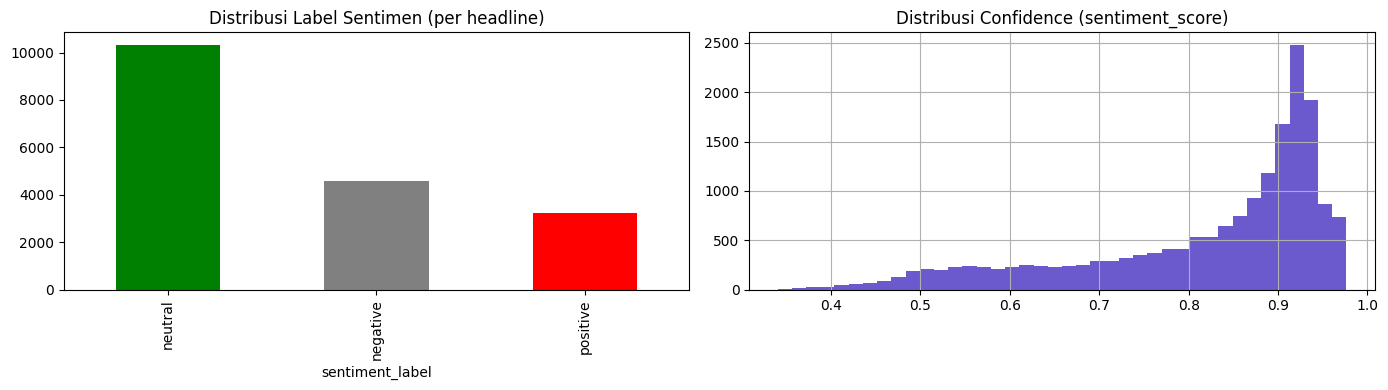

In [40]:
print('=== Distribusi Label ===')
print(scored['sentiment_label'].value_counts())
print(f"\nsentiment_score  mean : {scored['sentiment_score'].mean():.4f}")
print(scored['sentiment_score'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
scored['sentiment_label'].value_counts().plot(kind='bar', ax=axes[0],
    color=['green', 'gray', 'red'])
axes[0].set_title('Distribusi Label Sentimen (per headline)')
scored['sentiment_score'].hist(bins=40, ax=axes[1], color='slateblue')
axes[1].set_title('Distribusi Confidence (sentiment_score)')
plt.tight_layout(); plt.show()

## 3. Agregasi Harian — Probability-Weighted

**Perbaikan metodologi.** Versi lama mengagregasi rata-rata `sentiment_numeric` (-1/0/1) saja, sehingga mengabaikan seberapa yakin FinBERT. Versi ini memberi bobot confidence:

```
signed = sentiment_numeric * sentiment_score
```

Headline positif menyumbang `+prob`, negatif `-prob`, neutral `0`. Skor harian = rata-rata `signed` (range kira-kira [-1, 1], kontinu).

### 3.1 Hitung `signed` lalu groupby per hari

In [41]:
scored['signed'] = scored['sentiment_numeric'] * scored['sentiment_score']

def _prop(label):
    return lambda s: (s == label).mean()

daily = scored.groupby('Date').agg(
    headline_count=('Title', 'size'),
    sentiment_mean=('signed', 'mean'),                 # <- skor weighted baru
    sentiment_pos=('sentiment_label', _prop('positive')),
    sentiment_neg=('sentiment_label', _prop('negative')),
    sentiment_neu=('sentiment_label', _prop('neutral')),
).reset_index()

# Label harian dari tanda sentiment_mean dengan neutral band
NEUTRAL_BAND = 0.05
def _daily_label(x):
    if x > NEUTRAL_BAND:
        return 'positive'
    if x < -NEUTRAL_BAND:
        return 'negative'
    return 'neutral'

daily['sentiment_label'] = daily['sentiment_mean'].map(_daily_label)

# Skema kolom kompatibel dengan pipeline/feature_engineering/sentiment_aggregator.py
daily = daily[['Date', 'headline_count', 'sentiment_mean',
               'sentiment_pos', 'sentiment_neg', 'sentiment_neu', 'sentiment_label']]
print('Shape harian :', daily.shape)
print(daily['sentiment_mean'].describe())
daily.head()

Shape harian : (3504, 7)
count    3504.000000
mean       -0.069832
std         0.295762
min        -0.975366
25%        -0.222949
50%         0.000000
75%         0.001713
max         0.950584
Name: sentiment_mean, dtype: float64


,Date,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu,sentiment_label
0,2008-01-02,3,-0.522108,0.0,0.666667,0.333333,negative
1,2008-01-03,1,0.861627,1.0,0.000000,0.000000,positive
2,2008-01-07,1,0.586567,1.0,0.000000,0.000000,positive
3,2008-01-09,2,-0.421696,0.0,0.500000,0.500000,negative
4,2008-01-10,1,0.542341,1.0,0.000000,0.000000,positive


### 3.2 Time-series Sentimen Harian

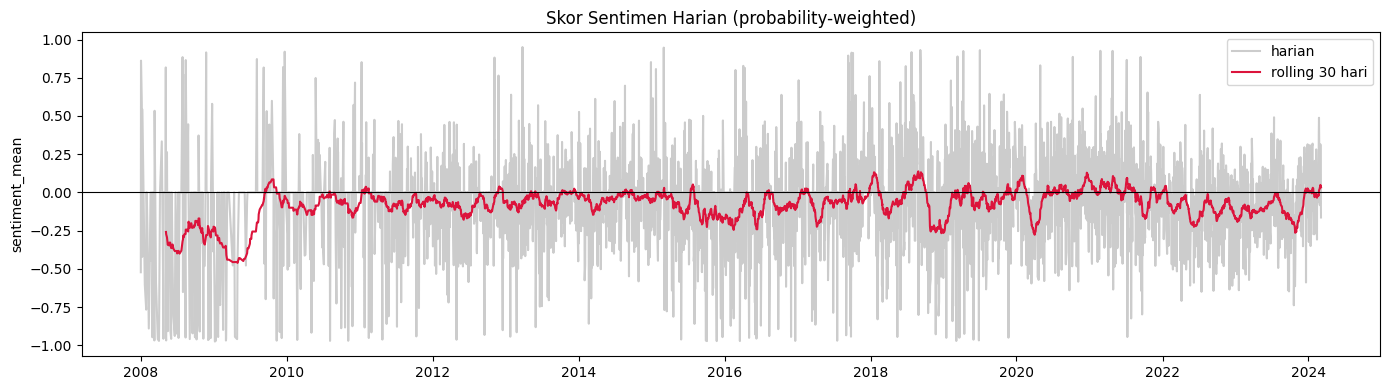

In [42]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily['Date'], daily['sentiment_mean'], color='gray', alpha=0.4, label='harian')
ax.plot(daily['Date'], daily['sentiment_mean'].rolling(30).mean(),
        color='crimson', label='rolling 30 hari')
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Skor Sentimen Harian (probability-weighted)')
ax.set_ylabel('sentiment_mean'); ax.legend()
plt.tight_layout(); plt.show()

### 3.3 Distribusi Skor Sentimen Harian

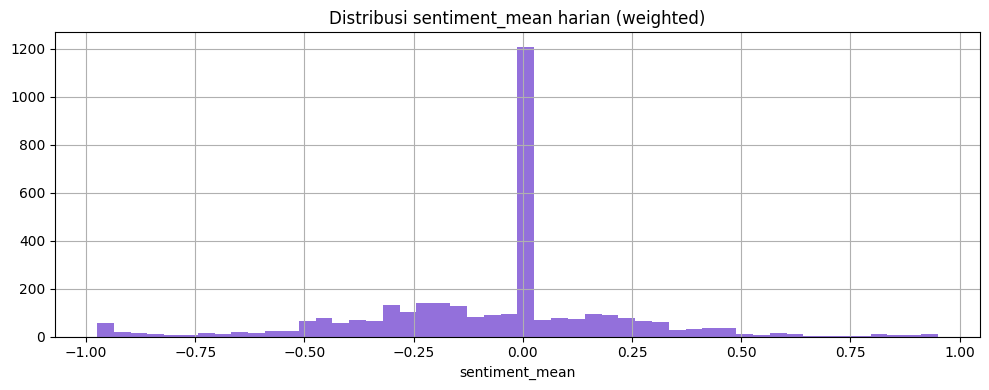

sentiment_label
negative    1371
neutral     1346
positive     787
Name: count, dtype: int64


In [43]:
fig, ax = plt.subplots(figsize=(10, 4))
daily['sentiment_mean'].hist(bins=50, ax=ax, color='mediumpurple')
ax.set_title('Distribusi sentiment_mean harian (weighted)')
ax.set_xlabel('sentiment_mean')
plt.tight_layout(); plt.show()

print(daily['sentiment_label'].value_counts())

### 3.4 Perbandingan Metode Lama vs Baru

Korelasi lama vs baru : 0.9815

Statistik:
       baru_weighted  lama_unweighted
count    3504.000000      3504.000000
mean       -0.069832        -0.075169
std         0.295762         0.365075
min        -0.975366        -1.000000
25%        -0.222949        -0.264035
50%         0.000000         0.000000
75%         0.001713         0.000000
max         0.950584         1.000000


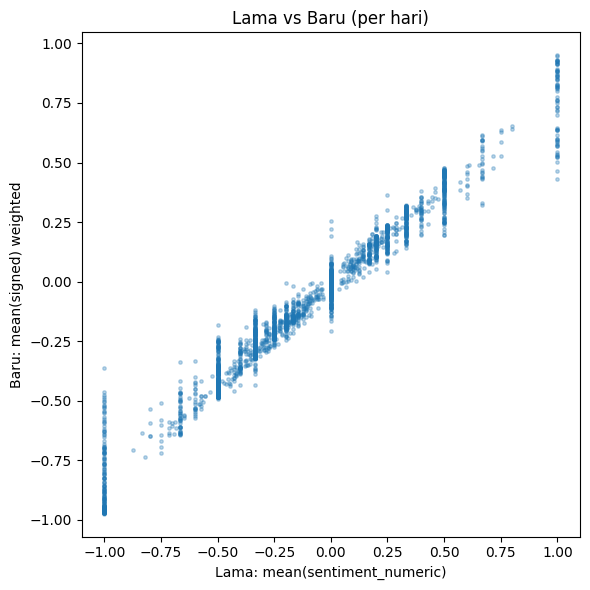

In [44]:
# Metode lama: rata-rata sentiment_numeric (-1/0/1), tanpa bobot confidence
old_mean = scored.groupby('Date')['sentiment_numeric'].mean()
cmp = daily.set_index('Date')[['sentiment_mean']].rename(columns={'sentiment_mean': 'baru_weighted'})
cmp['lama_unweighted'] = old_mean

print('Korelasi lama vs baru :', cmp['baru_weighted'].corr(cmp['lama_unweighted']).round(4))
print('\nStatistik:')
print(cmp.describe())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(cmp['lama_unweighted'], cmp['baru_weighted'], s=6, alpha=0.3)
ax.set_xlabel('Lama: mean(sentiment_numeric)')
ax.set_ylabel('Baru: mean(signed) weighted')
ax.set_title('Lama vs Baru (per hari)')
plt.tight_layout(); plt.show()

### 3.5 Ringkasan

| Langkah | Keterangan |
|---------|-----------|
| Load | 19.127 headline (2008–2024), kolom Title/Date/CP |
| Cleaning | strip + collapse whitespace + buang duplikat (Title+Date) + filter < 3 kata |
| Scoring | FinBERT per-headline → label + probabilitas |
| Agregasi | per hari, **sentiment_mean = mean(numeric × prob)** (probability-weighted) |

Hasil akhir berupa DataFrame `daily` di memori (skema kolom kompatibel dengan
`sentiment_aggregator.py`). **Tidak ada CSV yang ditulis ke project** — sesuai permintaan,
notebook ini hanya untuk eksplorasi dan dijalankan manual.

In [45]:
# DataFrame hasil akhir (siap dipakai / disimpan manual bila perlu)
daily.tail()

,Date,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu,sentiment_label
3499,2024-02-27,21,-0.083409,0.238095,0.333333,0.428571,negative
3500,2024-02-28,19,-0.074496,0.210526,0.263158,0.526316,negative
3501,2024-02-29,22,0.098995,0.363636,0.227273,0.409091,positive
3502,2024-03-01,30,0.314386,0.600000,0.200000,0.200000,positive
3503,2024-03-04,31,-0.163943,0.258065,0.419355,0.322581,negative


## 4. Simpan Output ke `data/processed/sentiment/`

Menyimpan dua file:
- `headlines_scored.csv`  — setiap headline + kolom sentimen (per baris berita)
- `headlines_daily_sentiment.csv` — agregasi harian (1 baris per hari, input pipeline LSTM)


In [46]:
from pathlib import Path

OUT_DIR = PROJECT_ROOT / 'data' / 'processed' / 'sentiment'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. Per-headline scored ---
path_scored = OUT_DIR / 'headlines_scored.csv'
scored.to_csv(path_scored, index=False)
print(f'[OK] headlines_scored.csv    — {len(scored):,} baris | {path_scored}')

# --- 2. Daily aggregation ---
path_daily = OUT_DIR / 'headlines_daily_sentiment.csv'
daily.to_csv(path_daily, index=False)
print(f'[OK] headlines_daily_sentiment.csv — {len(daily):,} baris | {path_daily}')

# Preview
print('\n=== Preview daily (5 baris terakhir) ===')
daily.tail()

[OK] headlines_scored.csv    — 18,129 baris | /home/forecasting_index_snp500/stock_prediction/data/processed/sentiment/headlines_scored.csv
[OK] headlines_daily_sentiment.csv — 3,504 baris | /home/forecasting_index_snp500/stock_prediction/data/processed/sentiment/headlines_daily_sentiment.csv

=== Preview daily (5 baris terakhir) ===


,Date,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu,sentiment_label
3499,2024-02-27,21,-0.083409,0.238095,0.333333,0.428571,negative
3500,2024-02-28,19,-0.074496,0.210526,0.263158,0.526316,negative
3501,2024-02-29,22,0.098995,0.363636,0.227273,0.409091,positive
3502,2024-03-01,30,0.314386,0.600000,0.200000,0.200000,positive
3503,2024-03-04,31,-0.163943,0.258065,0.419355,0.322581,negative


In [47]:
daily.shape[0]

3504